In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../dataset/Model_Dataset.csv')
X = df[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']]
y = df['price']

In [35]:
# cách 1: test_size = 0.2
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [48]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

mse_train = []
mse_test = []
Rsqu_train = []
Rsqu_test = []

order = [1, 2, 3]
for n in order:
    Input = [ ("ss", StandardScaler()),("pf", PolynomialFeatures(degree=n, include_bias=False)), ("m", LinearRegression()) ]
    pipe = Pipeline(Input)
    pipe.fit(x_train, y_train)

    mse_train.append(mean_squared_error(y_train, pipe.predict(x_train)))
    mse_test.append(mean_squared_error(y_test, pipe.predict(x_test)))

    Rsqu_train.append(pipe.score(x_train, y_train))
    Rsqu_test.append(pipe.score(x_test, y_test))

In [49]:
mse_train

[11213359.20451133, 8274294.1046753405, 5757366.382549638]

In [50]:
mse_test

[17478092.15583064, 19441604.373632476, 56306705.97852327]

In [51]:
Rsqu_train

[0.8103273093438823, 0.8600412599390891, 0.9026148049879708]

In [52]:
Rsqu_test

[0.7693279024384683, 0.7434138908959127, 0.25687621629151824]

Text(3, 56306705.97852327, 'test')

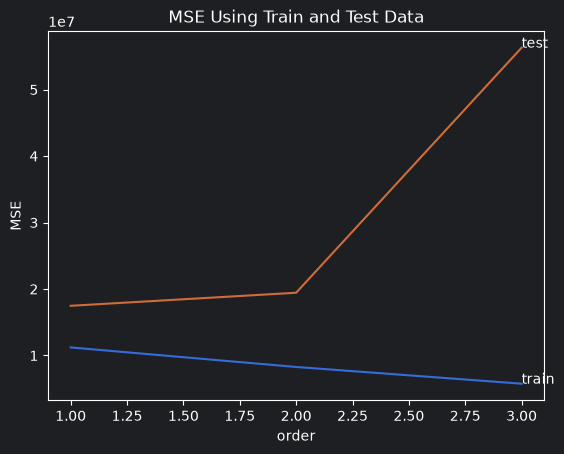

In [53]:
# vẽ hình giữa bậc và mse
plt.plot(order, mse_train)
plt.plot(order, mse_test)
plt.xlabel('order')
plt.ylabel('MSE')
plt.title('MSE Using Train and Test Data')
plt.text(3, mse_train[-1], 'train')
plt.text(3, mse_test[-1], 'test')

Text(3, 0.25687621629151824, 'test')

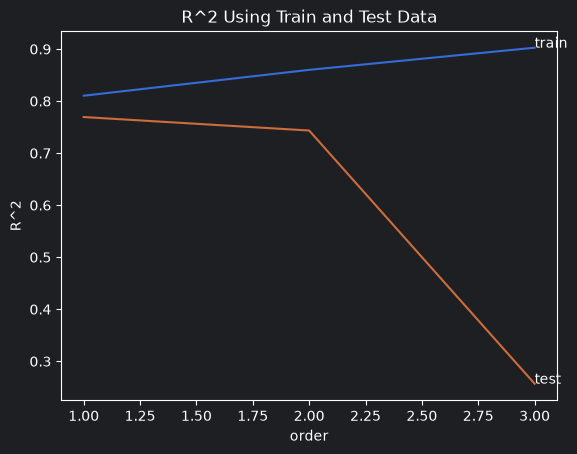

In [55]:
# vẽ hình giữa bậc và r2
plt.plot(order, Rsqu_train)
plt.plot(order, Rsqu_test)
plt.xlabel('order')
plt.ylabel('R^2')
plt.title('R^2 Using Train and Test Data')
plt.text(3, Rsqu_train[-1], 'train')
plt.text(3, Rsqu_test[-1], 'test')

Text(3, 0.25687621629151824, 'test')

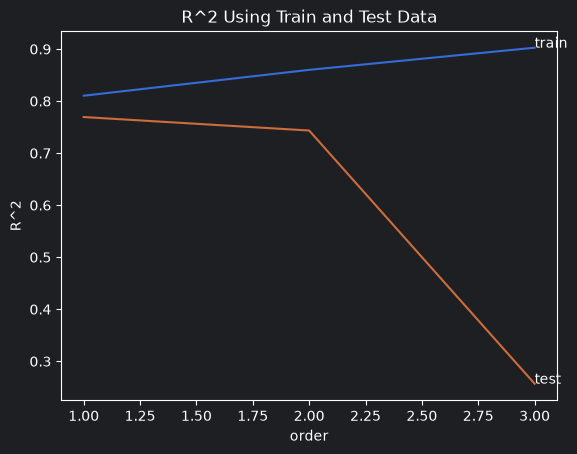

In [55]:
# vẽ hình giữa bậc và r2
plt.plot(order, Rsqu_train)
plt.plot(order, Rsqu_test)
plt.xlabel('order')
plt.ylabel('R^2')
plt.title('R^2 Using Train and Test Data')
plt.text(3, Rsqu_train[-1], 'train')
plt.text(3, Rsqu_test[-1], 'test')